In [50]:
# Import required libraries
import pandas as pd
from pathlib import Path

# Check current working directory
print("Working directory:", Path.cwd())

# Find the dataset regardless of whether Jupyter
# starts from OIBSIP or the Task 3 folder
possible_paths = [
    Path("data/car_details.csv"),
    Path("DataScience-Task3-CarPricePrediction/data/car_details.csv")
]

dataset_path = next(
    (path for path in possible_paths if path.is_file()),
    None
)

if dataset_path is None:
    raise FileNotFoundError(
        "Cannot find car_details.csv. Check the data folder."
    )

# Load the dataset
df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display the first five records
display(df.head())

# Display column names
print("\nDataset columns:")
print(df.columns.tolist())

Working directory: c:\Users\HP OMNI BOOK X\Documents\OIBSIP\DataScience-Task3-CarPricePrediction
Dataset loaded successfully!
Dataset shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner



Dataset columns:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


## 2. Data Cleaning and Preprocessing

Data cleaning is an essential stage of the machine learning
workflow. It involves identifying and correcting issues
that could affect model performance.

In this section, we will:

1. Inspect dataset dimensions and column names.
2. Check data types.
3. Identify missing values.
4. Check duplicate records.
5. Examine inconsistent categorical values.
6. Validate numerical features.
7. Prepare a clean dataset for further analysis.

In [51]:
# Display dataset dimensions
print("Dataset Shape:", df.shape)

print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display dataset information
print("\nDataset Information:")
df.info()

# Display numerical descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe())

Dataset Shape: (4340, 8)

Number of rows: 4340
Number of columns: 8

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 271.4 KB

Descriptive Statistics:


,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [52]:
# Check missing values in each column
print("Missing Values per Column:")
print(df.isnull().sum())

# Calculate total missing values
total_missing = df.isnull().sum().sum()

print("\nTotal Missing Values:", total_missing)

# Calculate percentage of missing values
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print("\nMissing Value Percentages:")
print(missing_percentage.round(2))

Missing Values per Column:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Total Missing Values: 0

Missing Value Percentages:
name             0.0
year             0.0
selling_price    0.0
km_driven        0.0
fuel             0.0
seller_type      0.0
transmission     0.0
owner            0.0
dtype: float64


In [53]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# Display example duplicates, if present
if duplicate_count > 0:
    print("\nSample duplicate records:")
    display(df[df.duplicated(keep=False)].head(10))
else:
    print("No duplicate rows found.")

Number of duplicate rows: 763

Sample duplicate records:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner
5,Maruti Alto LX BSIII,2007,140000,125000,Petrol,Individual,Manual,First Owner
6,Hyundai Xcent 1.2 Kappa S,2016,550000,25000,Petrol,Individual,Manual,First Owner
7,Tata Indigo Grand Petrol,2014,240000,60000,Petrol,Individual,Manual,Second Owner
8,Hyundai Creta 1.6 VTVT S,2015,850000,25000,Petrol,Individual,Manual,First Owner
9,Maruti Celerio Green VXI,2017,365000,78000,CNG,Individual,Manual,First Owner


In [54]:
# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=["object", "str", "category"]
).columns

print("Categorical Columns:")
print(categorical_columns.tolist())

# Inspect unique values
for column in categorical_columns:

    print(f"\nColumn: {column}")

    print("Number of unique values:",
          df[column].nunique())

    print(df[column].value_counts().head(15))

Categorical Columns:
['name', 'fuel', 'seller_type', 'transmission', 'owner']

Column: name
Number of unique values: 1491
name
Maruti Swift Dzire VDI      69
Maruti Alto 800 LXI         59
Maruti Alto LXi             47
Hyundai EON Era Plus        35
Maruti Alto LX              35
Maruti Wagon R VXI BS IV    29
Maruti Swift VDI BSIV       29
Maruti Swift VDI            27
Maruti Wagon R LXI Minor    24
Hyundai EON Magna Plus      24
Maruti 800 AC               23
Maruti Wagon R LXI          23
Mahindra XUV500 W8 2WD      22
Maruti Ritz VDi             22
Hyundai i10 Magna           22
Name: count, dtype: int64

Column: fuel
Number of unique values: 5
fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64

Column: seller_type
Number of unique values: 3
seller_type
Individual          3244
Dealer               994
Trustmark Dealer     102
Name: count, dtype: int64

Column: transmission
Number of unique values: 2
transmission
Ma

In [55]:
# Inspect numerical features
numerical_columns = [
    "year",
    "selling_price",
    "km_driven"
]

for column in numerical_columns:

    print(f"\n{column}")

    print("Data type:", df[column].dtype)

    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())

# Check potentially invalid values
print("\nInvalid price records:",
      (df["selling_price"] <= 0).sum())

print("Negative mileage records:",
      (df["km_driven"] < 0).sum())

print("Invalid manufacturing years:",
      ((df["year"] < 1900) |
       (df["year"] > 2026)).sum())


year
Data type: int64
Minimum: 1992
Maximum: 2020

selling_price
Data type: int64
Minimum: 20000
Maximum: 8900000

km_driven
Data type: int64
Minimum: 1
Maximum: 806599

Invalid price records: 0
Negative mileage records: 0
Invalid manufacturing years: 0


## 3. Data Cleaning

The original dataset is preserved, while a working copy
is created for cleaning.

Categorical values are standardized, duplicate records
are examined, and invalid or missing numerical values
are identified.

The cleaned dataset will be used for feature engineering
and exploratory data analysis.

In [56]:
# Create a copy of the original dataset
df_clean = df.copy()

# Standardize categorical text fields
category_columns = [
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

for column in category_columns:

    df_clean[column] = (
        df_clean[column]
        .astype("string")
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
    )

# Clean car names
df_clean["name"] = (
    df_clean["name"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Convert numerical columns
for column in ["year", "selling_price", "km_driven"]:

    df_clean[column] = pd.to_numeric(
        df_clean[column],
        errors="coerce"
    )

# Display the cleaned data preview
print("Cleaning preparation completed!")

display(df_clean.head())

Cleaning preparation completed!


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,petrol,individual,manual,first owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,petrol,individual,manual,first owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,diesel,individual,manual,first owner
3,Datsun RediGO T Option,2017,250000,46000,petrol,individual,manual,first owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,diesel,individual,manual,second owner


## 4. Feature Engineering

Feature engineering involves transforming existing data
into meaningful variables that can improve model performance.

In this project, two new features are created:

1. Car Age:
   Calculated from the vehicle's manufacturing year.

2. Car Brand:
   Extracted from the vehicle's name.

These features help the machine learning models understand
how vehicle age and manufacturer influence selling prices.

## 4. Feature Engineering

Feature engineering involves transforming existing data
into meaningful variables that can improve model performance.

In this project, two new features are created:

1. Car Age:
   Calculated from the vehicle's manufacturing year.

2. Car Brand:
   Extracted from the vehicle's name.

These features help the machine learning models understand
how vehicle age and manufacturer influence selling prices.

In [57]:
# Preserve the cleaned dataset
df_model = df_clean.copy()

# Record the number of rows before filtering
original_rows = len(df_model)

# Remove records missing essential information
required_columns = [
    "name", "year", "selling_price", "km_driven"
]

df_model = df_model.dropna(subset=required_columns)

# Remove impossible numerical values
df_model = df_model[
    (df_model["selling_price"] > 0) &
    (df_model["km_driven"] >= 0) &
    (df_model["year"] >= 1900) &
    (df_model["year"] <= 2026)
].copy()

# Remove records with empty car names
df_model = df_model[
    df_model["name"].str.len().fillna(0) > 0
].copy()

print("Records before filtering:", original_rows)
print("Records after filtering:", len(df_model))
print("Records removed:", original_rows - len(df_model))

Records before filtering: 4340
Records after filtering: 4340
Records removed: 0


In [58]:
# Reference year used for feature engineering
REFERENCE_YEAR = 2026

# Calculate vehicle age
df_model["car_age"] = (
    REFERENCE_YEAR - df_model["year"]
)

# Display manufacturing year and calculated age
display(
    df_model[["name", "year", "car_age"]].head(10)
)

,name,year,car_age
0,Maruti 800 AC,2007,19
1,Maruti Wagon R LXI Minor,2007,19
2,Hyundai Verna 1.6 SX,2012,14
3,Datsun RediGO T Option,2017,9
4,Honda Amaze VX i-DTEC,2014,12
5,Maruti Alto LX BSIII,2007,19
6,Hyundai Xcent 1.2 Kappa S,2016,10
7,Tata Indigo Grand Petrol,2014,12
8,Hyundai Creta 1.6 VTVT S,2015,11
9,Maruti Celerio Green VXI,2017,9


In [59]:
# Function to extract brand from car name
def extract_brand(car_name):

    name = str(car_name).strip()
    words = name.split()

    if not words:
        return "unknown"

    # Handle selected multi-word brands
    if len(words) >= 2:
        first_two = " ".join(words[:2]).lower()

        if first_two in [
            "land rover",
            "rolls royce",
            "aston martin"
        ]:
            return " ".join(words[:2]).title()

    return words[0].title()


# Create the brand column
df_model["brand"] = df_model["name"].apply(
    extract_brand
)

# Display results
display(
    df_model[["name", "brand"]].head(15)
)

,name,brand
0,Maruti 800 AC,Maruti
1,Maruti Wagon R LXI Minor,Maruti
2,Hyundai Verna 1.6 SX,Hyundai
3,Datsun RediGO T Option,Datsun
4,Honda Amaze VX i-DTEC,Honda
5,Maruti Alto LX BSIII,Maruti
6,Hyundai Xcent 1.2 Kappa S,Hyundai
7,Tata Indigo Grand Petrol,Tata
8,Hyundai Creta 1.6 VTVT S,Hyundai
9,Maruti Celerio Green VXI,Maruti


Number of unique brands:
29

Top 15 car brands:
brand
Maruti        1280
Hyundai        821
Mahindra       365
Tata           361
Honda          252
Ford           238
Toyota         206
Chevrolet      188
Renault        146
Volkswagen     107
Skoda           68
Nissan          64
Audi            60
Bmw             39
Datsun          37
Name: count, dtype: Int64


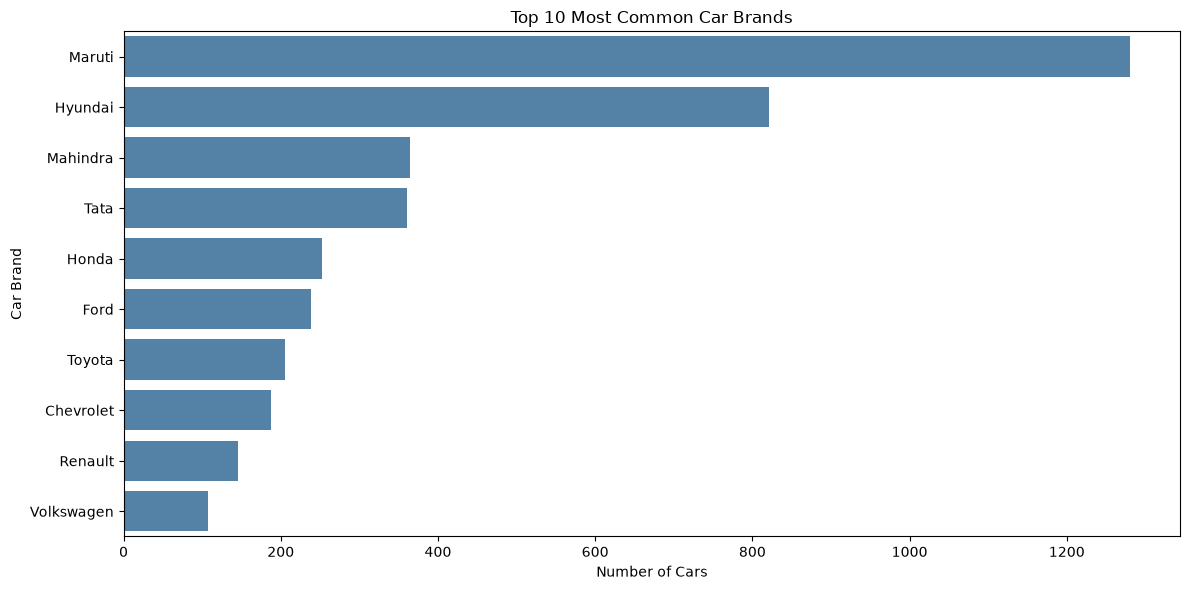

In [60]:
# Count vehicles by brand
brand_counts = df_model["brand"].value_counts()

print("Number of unique brands:")
print(df_model["brand"].nunique())

print("\nTop 15 car brands:")
print(brand_counts.head(15))

# Visualize the 10 most common brands
plt.figure(figsize=(12, 6))

sns.barplot(
    x=brand_counts.head(10).values,
    y=brand_counts.head(10).index,
    color="steelblue"
)

plt.title("Top 10 Most Common Car Brands")
plt.xlabel("Number of Cars")
plt.ylabel("Car Brand")

plt.tight_layout()
plt.show()

In [61]:
# Display the updated dataset
print("Updated dataset shape:", df_model.shape)

# Inspect engineered features
display(
    df_model[
        [
            "name",
            "brand",
            "year",
            "car_age",
            "km_driven",
            "selling_price"
        ]
    ].head(10)
)

# Check missing values in new columns
print("\nMissing values in engineered features:")
print(df_model[["brand", "car_age"]].isnull().sum())

# Summarize car age
print("\nCar Age Statistics:")
display(df_model["car_age"].describe())

Updated dataset shape: (4340, 10)


,name,brand,year,car_age,km_driven,selling_price
0,Maruti 800 AC,Maruti,2007,19,70000,60000
1,Maruti Wagon R LXI Minor,Maruti,2007,19,50000,135000
2,Hyundai Verna 1.6 SX,Hyundai,2012,14,100000,600000
3,Datsun RediGO T Option,Datsun,2017,9,46000,250000
4,Honda Amaze VX i-DTEC,Honda,2014,12,141000,450000
5,Maruti Alto LX BSIII,Maruti,2007,19,125000,140000
6,Hyundai Xcent 1.2 Kappa S,Hyundai,2016,10,25000,550000
7,Tata Indigo Grand Petrol,Tata,2014,12,60000,240000
8,Hyundai Creta 1.6 VTVT S,Hyundai,2015,11,25000,850000
9,Maruti Celerio Green VXI,Maruti,2017,9,78000,365000



Missing values in engineered features:
brand      0
car_age    0
dtype: int64

Car Age Statistics:


count    4340.000000
mean       12.909217
std         4.215344
min         6.000000
25%        10.000000
50%        12.000000
75%        15.000000
max        34.000000
Name: car_age, dtype: float64

### Feature Engineering Observations

Two new variables were successfully created:

1. **Car Age:** Represents the difference between
   the reference year and the manufacturing year.

2. **Car Brand:** Identifies the vehicle manufacturer
   from the car name.

Car age may help capture vehicle depreciation patterns,
while brand may represent differences in market value,
reliability, and consumer preferences.

These engineered features will be included in the
regression models to help predict used-car selling prices.

Since the dataset contains historical prices, using
2026 as the reference year is an analytical convention
and does not represent each vehicle's age at sale.

In [62]:
# Verify the newly created features
print("Dataset shape:", df_model.shape)

print("\nEngineered features:")
display(
    df_model[
        ["name", "brand", "year", "car_age", "selling_price"]
    ].head()
)

print("\nMissing values:")
print(df_model[["brand", "car_age"]].isnull().sum())

Dataset shape: (4340, 10)

Engineered features:


,name,brand,year,car_age,selling_price
0,Maruti 800 AC,Maruti,2007,19,60000
1,Maruti Wagon R LXI Minor,Maruti,2007,19,135000
2,Hyundai Verna 1.6 SX,Hyundai,2012,14,600000
3,Datsun RediGO T Option,Datsun,2017,9,250000
4,Honda Amaze VX i-DTEC,Honda,2014,12,450000



Missing values:
brand      0
car_age    0
dtype: int64


## 6. Data Preprocessing for Machine Learning

Data preprocessing transforms the cleaned dataset into
a format suitable for machine learning algorithms.

The target variable is `selling_price`, while the
predictor variables include:

- Car age
- Kilometers driven
- Car brand
- Fuel type
- Seller type
- Transmission type
- Ownership category

Categorical features will be converted into numerical
representations using One-Hot Encoding.

Numerical features will be standardized for the Linear
Regression model.

The dataset will be divided into 80% training data
and 20% testing data.

All preprocessing transformations will be fitted using
the training data only to prevent data leakage.

In [63]:
# Create a working dataset for machine learning
df_ml = df_model.copy()

# Remove exact duplicate records before splitting
duplicate_count = df_ml.duplicated().sum()

print("Exact duplicate records:", duplicate_count)

df_ml = df_ml.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df_ml.shape)

# Select features for predicting selling price
feature_columns = [
    "car_age",
    "km_driven",
    "brand",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

# Define independent variables
X = df_ml[feature_columns].copy()

# Define dependent variable
y = df_ml["selling_price"].copy()

# Display dataset dimensions
print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

# Display selected input features
print("\nSelected Features:")
print(X.columns.tolist())

# Display first five rows
display(X.head())

Exact duplicate records: 763
Dataset shape after removing duplicates: (3577, 10)

Feature matrix shape: (3577, 7)
Target vector shape: (3577,)

Selected Features:
['car_age', 'km_driven', 'brand', 'fuel', 'seller_type', 'transmission', 'owner']


,car_age,km_driven,brand,fuel,seller_type,transmission,owner
0,19,70000,Maruti,petrol,individual,manual,first owner
1,19,50000,Maruti,petrol,individual,manual,first owner
2,14,100000,Hyundai,diesel,individual,manual,first owner
3,9,46000,Datsun,petrol,individual,manual,first owner
4,12,141000,Honda,diesel,individual,manual,second owner


In [64]:
# Numerical input features
numerical_features = [
    "car_age",
    "km_driven"
]

# Categorical input features
categorical_features = [
    "brand",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

# Verify feature data types
print("\nFeature Data Types:")
print(X.dtypes)

Numerical Features:
['car_age', 'km_driven']

Categorical Features:
['brand', 'fuel', 'seller_type', 'transmission', 'owner']

Feature Data Types:
car_age          int64
km_driven        int64
brand           string
fuel            string
seller_type     string
transmission    string
owner           string
dtype: object


In [65]:
# Import train-test splitting function
from sklearn.model_selection import train_test_split

# Divide dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display results
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining percentage:",
      round(len(X_train) / len(X) * 100, 2))

print("Testing percentage:",
      round(len(X_test) / len(X) * 100, 2))

Training features: (2861, 7)
Testing features: (716, 7)
Training target: (2861,)
Testing target: (716,)

Training percentage: 79.98
Testing percentage: 20.02


### Preprocessing Pipeline

Two types of preprocessing are applied.

**Numerical Features**
- Missing values are replaced with the training median.
- StandardScaler standardizes numerical measurements.

**Categorical Features**
- Missing values are replaced with the most frequent category.
- One-Hot Encoding converts categories into numerical columns.

ColumnTransformer combines these transformations.

Using a preprocessing pipeline prevents test data
from influencing the transformations learned
during model training.

In [66]:
# Import preprocessing utilities
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Convert nullable pandas strings to ordinary object columns,
# representing missing values consistently as np.nan
for column in categorical_features:
    X_train[column] = X_train[column].astype(object)
    X_test[column] = X_test[column].astype(object)

    X_train[column] = X_train[column].where(
        pd.notna(X_train[column]), np.nan
    )

    X_test[column] = X_test[column].where(
        pd.notna(X_test[column]), np.nan
    )

# Pipeline for numerical variables
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline for categorical variables
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [67]:
# Confirm that the data is ready for model training

print("DATA PREPARATION SUMMARY")
print("=" * 45)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nNumber of input features:", X_train.shape[1])

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTarget variable: selling_price")

print("\nPreprocessing pipeline:",
      type(preprocessor).__name__)

print("\nData preparation completed successfully!")

DATA PREPARATION SUMMARY
Training observations: 2861
Testing observations: 716

Number of input features: 7

Numerical features:
['car_age', 'km_driven']

Categorical features:
['brand', 'fuel', 'seller_type', 'transmission', 'owner']

Target variable: selling_price

Preprocessing pipeline: ColumnTransformer

Data preparation completed successfully!


### Data Preprocessing Observations

The dataset was successfully prepared for machine learning.

Seven predictor variables were selected, consisting of
two numerical features and five categorical features.

Exact duplicate records were removed before splitting
the dataset to reduce potential information leakage.

An 80/20 train-test split was applied.

Numerical variables will be imputed and standardized,
while categorical variables will be imputed and encoded
using One-Hot Encoding.

The transformations are implemented through scikit-learn
pipelines to maintain a consistent and reproducible
machine learning workflow.

The processed data is now ready for regression
model training.

## 7. Machine Learning Model Training

The objective of this stage is to train regression models
capable of predicting used-car selling prices based on
vehicle characteristics.

Two machine learning algorithms are implemented:

1. Linear Regression
2. Random Forest Regressor

Linear Regression serves as the baseline model.

Random Forest Regressor is used to capture more complex
relationships between vehicle characteristics and prices.

Both algorithms use the same training dataset.

Preprocessing is incorporated into each model pipeline,
ensuring consistent transformations and preventing
information leakage from the test dataset.

In [68]:
# Import machine learning regression algorithms
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Import pipeline and cloning utilities
from sklearn.pipeline import Pipeline
from sklearn.base import clone

print("Regression algorithms imported successfully!")

Regression algorithms imported successfully!


### 7.1 Linear Regression

Linear Regression is used as the baseline prediction model.

The algorithm estimates a car's selling price using a
linear combination of its numerical and encoded
categorical features.

The model is trained using the prepared training dataset.

A preprocessing pipeline handles missing values,
feature scaling, and categorical encoding before
model training.

Its performance will be compared with Random Forest
Regression.

In [69]:
# Create a Linear Regression pipeline
linear_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("regressor", LinearRegression())
])

# Train Linear Regression on training data only
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

# Generate predictions on the test dataset
linear_predictions = linear_model.predict(X_test)

# Display the first five predictions
print("\nFirst five predicted selling prices (INR):")

for price in linear_predictions[:5]:
    print(f"INR {price:,.2f}")

Linear Regression model trained successfully!

First five predicted selling prices (INR):
INR 527,597.48
INR 470,512.75
INR 954,227.41
INR 2,035,905.17
INR 142,903.77


### 7.2 Random Forest Regression

Random Forest Regressor is an ensemble learning algorithm
that combines predictions from multiple decision trees.

Each decision tree learns relationships between
vehicle characteristics and selling prices.

The final prediction is obtained by averaging the
predictions from the individual trees.

Random Forest can model nonlinear relationships and
interactions between features.

For this project, the model uses 150 decision trees
with a fixed random state for reproducibility.

In [70]:
# Create a Random Forest regression pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("regressor", RandomForestRegressor(
        n_estimators=150,
        max_depth=18,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the Random Forest model
rf_model.fit(X_train, y_train)

print("Random Forest Regressor trained successfully!")

# Generate predictions
rf_predictions = rf_model.predict(X_test)

# Display the first five predictions
print("\nFirst five predicted selling prices (INR):")

for price in rf_predictions[:5]:
    print(f"INR {price:,.2f}")

Random Forest Regressor trained successfully!

First five predicted selling prices (INR):
INR 560,208.63
INR 453,621.30
INR 1,229,648.71
INR 2,448,037.92
INR 232,865.53


### 7.3 Actual Versus Predicted Selling Prices

The trained models are used to predict vehicle prices
from the reserved test dataset.

The predicted values are compared against the actual
selling prices.

This initial comparison provides an indication of
the differences between model predictions and real
recorded prices.

Formal evaluation will be performed using MAE,
RMSE, and R² score.

In [71]:
# Create a DataFrame to compare predictions
prediction_comparison = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Linear Regression": linear_predictions,
    "Random Forest": rf_predictions
})

# Add prediction errors for each model
prediction_comparison["Linear Error"] = (
    prediction_comparison["Actual Price"]
    - prediction_comparison["Linear Regression"]
)

prediction_comparison["RF Error"] = (
    prediction_comparison["Actual Price"]
    - prediction_comparison["Random Forest"]
)

# Display the first 10 predictions
display(prediction_comparison.head(10).round(2))

,Actual Price,Linear Regression,Random Forest,Linear Error,RF Error
0,270000,527597.48,560208.63,-257597.48,-290208.63
1,525000,470512.75,453621.30,54487.25,71378.70
2,990000,954227.41,1229648.71,35772.59,-239648.71
3,3800000,2035905.17,2448037.92,1764094.83,1351962.08
4,229999,142903.77,232865.53,87095.23,-2866.53
5,325000,376689.19,318499.37,-51689.19,6500.63
6,210000,168008.30,174850.08,41991.70,35149.92
7,500000,530721.55,678282.74,-30721.55,-178282.74
8,790000,801827.82,920727.80,-11827.82,-130727.80
9,360000,418050.50,534125.26,-58050.50,-174125.26


In [72]:
# Store trained regression models
regression_models = {
    "Linear Regression": linear_model,
    "Random Forest": rf_model
}

print("Successfully trained regression models:")

for model_name in regression_models:
    print("-", model_name)

print("\nTotal models trained:", len(regression_models))

Successfully trained regression models:
- Linear Regression
- Random Forest

Total models trained: 2


### Model Training Observations

Two machine learning regression models were successfully
trained to predict used-car selling prices.

**Linear Regression**

This model provides a baseline for understanding how
vehicle features relate linearly to selling prices.

**Random Forest Regressor**

This model combines multiple decision trees and can
capture more complex relationships among car age,
mileage, brand, fuel type, and other variables.

Both models were trained using 80% of the prepared
dataset and generated predictions for the reserved
20% test dataset.

The next stage will evaluate their predictive accuracy
using Mean Absolute Error (MAE), Root Mean Squared Error
(RMSE), and R² score.

The better-performing model will be identified using
the evaluation results rather than assumptions.

## 8. Model Evaluation and Comparison

This section evaluates the performance of two machine
learning regression models:

1. Linear Regression
2. Random Forest Regressor

The models are evaluated using the reserved test dataset.

Three evaluation metrics are calculated:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R-squared (R²)

MAE measures the average absolute prediction error.

RMSE penalizes larger prediction errors more heavily.

R² measures how well the model explains variation
in used-car selling prices.

The objective is to identify the most accurate model
based on actual evaluation results.

In [73]:
# Import regression evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Regression evaluation libraries imported successfully!")

Regression evaluation libraries imported successfully!


In [74]:
# Store evaluation results
evaluation_results = []

# Evaluate both regression models
for model_name, model in regression_models.items():

    # Predict selling prices
    y_pred = model.predict(X_test)

    # Mean Absolute Error
    mae = mean_absolute_error(y_test, y_pred)

    # Root Mean Squared Error
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    # R-squared score
    r2 = r2_score(y_test, y_pred)

    # Store the results
    evaluation_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    # Display evaluation results
    print("=" * 50)
    print("Model:", model_name)
    print("=" * 50)

    print(f"MAE: INR {mae:,.2f}")
    print(f"RMSE: INR {rmse:,.2f}")
    print(f"R² Score: {r2:.4f}")

    print()

Model: Linear Regression
MAE: INR 179,642.13
RMSE: INR 384,722.83
R² Score: 0.5405

Model: Random Forest
MAE: INR 156,819.27
RMSE: INR 359,726.55
R² Score: 0.5983



### 8.1 Regression Model Comparison

The evaluation results are summarized in a comparison
table showing MAE, RMSE, and R² for each model.

The model with the lowest RMSE will be selected as
the best-performing model.

MAE and R² will be considered as supporting metrics.

In [75]:
# Convert results into a DataFrame
results_df = pd.DataFrame(evaluation_results)

# Sort models by RMSE, then MAE
results_df = results_df.sort_values(
    by=["RMSE", "MAE"],
    ascending=True
).reset_index(drop=True)

# Display formatted comparison table
display(
    results_df.style.format({
        "MAE": "INR {:,.2f}",
        "RMSE": "INR {:,.2f}",
        "R2 Score": "{:.4f}"
    })
)

,Model,MAE,RMSE,R2 Score
0,Random Forest,"INR 156,819.27","INR 359,726.55",0.5983
1,Linear Regression,"INR 179,642.13","INR 384,722.83",0.5405


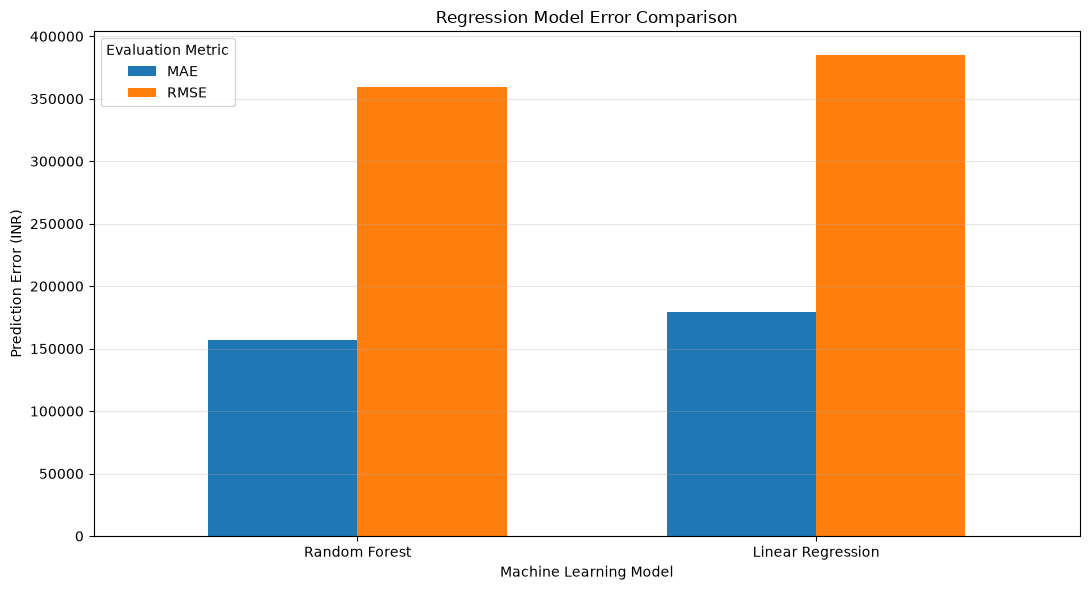

In [76]:
# Prepare evaluation metrics for visualization
plot_df = results_df.set_index("Model")[["MAE", "RMSE"]]

# Plot the evaluation errors
ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.65
)

plt.title("Regression Model Error Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Prediction Error (INR)")
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Best-Performing Regression Model

The best-performing regression model is selected
based on its predictive accuracy on the test dataset.

RMSE is used as the primary evaluation metric
because larger prediction errors can be particularly
important when estimating vehicle prices.

MAE is used as a secondary metric.

The selected model will be used for further
prediction analysis and interpretation.

In [77]:
# Select the best-performing model
best_model_name = results_df.iloc[0]["Model"]

# Retrieve evaluation metrics
best_mae = results_df.iloc[0]["MAE"]
best_rmse = results_df.iloc[0]["RMSE"]
best_r2 = results_df.iloc[0]["R2 Score"]

# Retrieve the actual trained model
best_model = regression_models[best_model_name]

print("BEST-PERFORMING REGRESSION MODEL")
print("=" * 45)

print("Model:", best_model_name)
print(f"MAE: INR {best_mae:,.2f}")
print(f"RMSE: INR {best_rmse:,.2f}")
print(f"R² Score: {best_r2:.4f}")

print("\nThe model was selected based on")
print("the lowest RMSE, using MAE as a tie-breaker.")

BEST-PERFORMING REGRESSION MODEL
Model: Random Forest
MAE: INR 156,819.27
RMSE: INR 359,726.55
R² Score: 0.5983

The model was selected based on
the lowest RMSE, using MAE as a tie-breaker.


## 10. Actual Versus Predicted Selling Prices

This section visualizes the relationship between
actual and predicted used-car prices.

A scatter plot is used to assess how closely the
model's predictions align with the actual values.

Points near the diagonal reference line indicate
more accurate predictions.

Large deviations from the line indicate
prediction errors.

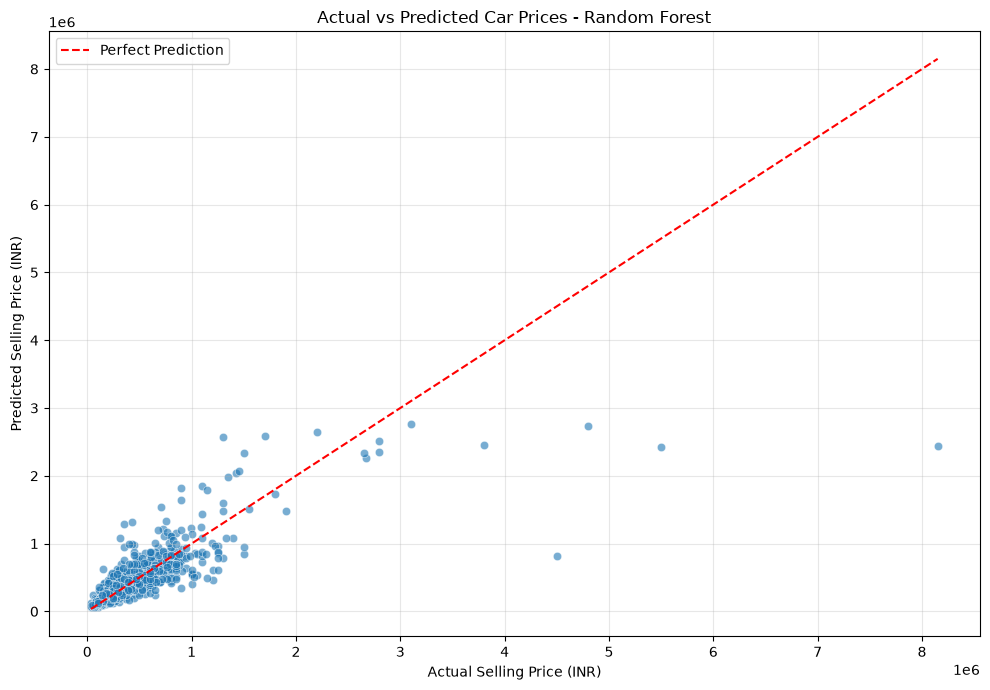

In [78]:
# Generate predictions using the best model
best_predictions = best_model.predict(X_test)

# Plot actual versus predicted prices
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=y_test,
    y=best_predictions,
    alpha=0.6
)

# Draw perfect-prediction reference line
min_price = min(y_test.min(), best_predictions.min())
max_price = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--",
    label="Perfect Prediction"
)

plt.title(
    f"Actual vs Predicted Car Prices - {best_model_name}"
)

plt.xlabel("Actual Selling Price (INR)")
plt.ylabel("Predicted Selling Price (INR)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Residual Analysis

Residual analysis helps assess prediction errors.

A residual represents the difference between an
actual selling price and the predicted price.

Residuals close to zero indicate accurate predictions.

A random pattern around zero suggests that the
model has captured much of the predictable structure.

Systematic patterns may indicate that the model
is missing important relationships.

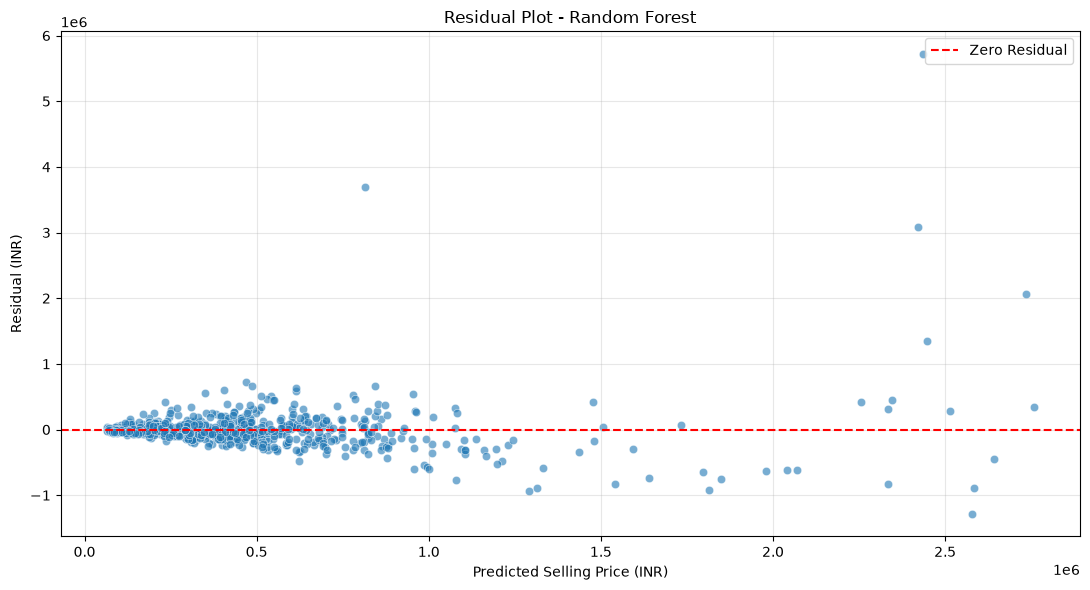

In [79]:
# Calculate residuals for the best model
residuals = y_test.to_numpy() - best_predictions

# Plot residuals against predicted prices
plt.figure(figsize=(11, 6))

sns.scatterplot(
    x=best_predictions,
    y=residuals,
    alpha=0.6
)

# Add horizontal zero-error reference line
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Residual"
)

plt.title(f"Residual Plot - {best_model_name}")
plt.xlabel("Predicted Selling Price (INR)")
plt.ylabel("Residual (INR)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 12. Feature Importance Analysis

Feature importance analysis helps identify which
vehicle characteristics contribute most to
prediction performance.

Permutation importance is used to examine the
contribution of each input feature.

The method measures how much model performance
worsens when the values of an individual feature
are randomly shuffled.

Features that cause larger increases in prediction
error are considered more important for the model.

This analysis supports model interpretation but
does not establish causal relationships.

In [80]:
# Import permutation importance
from sklearn.inspection import permutation_importance

# Calculate importance for the best model
importance_results = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=1
)

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_results.importances_mean,
    "Std": importance_results.importances_std
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance Results:")
display(importance_df.round(2))

Feature Importance Results:


,Feature,Importance,Std
0,car_age,110016.04,3500.89
3,fuel,57123.27,7485.87
5,transmission,50437.29,2303.28
2,brand,36810.26,4320.91
1,km_driven,18049.91,3856.05
4,seller_type,1490.07,118.79
6,owner,834.35,735.85


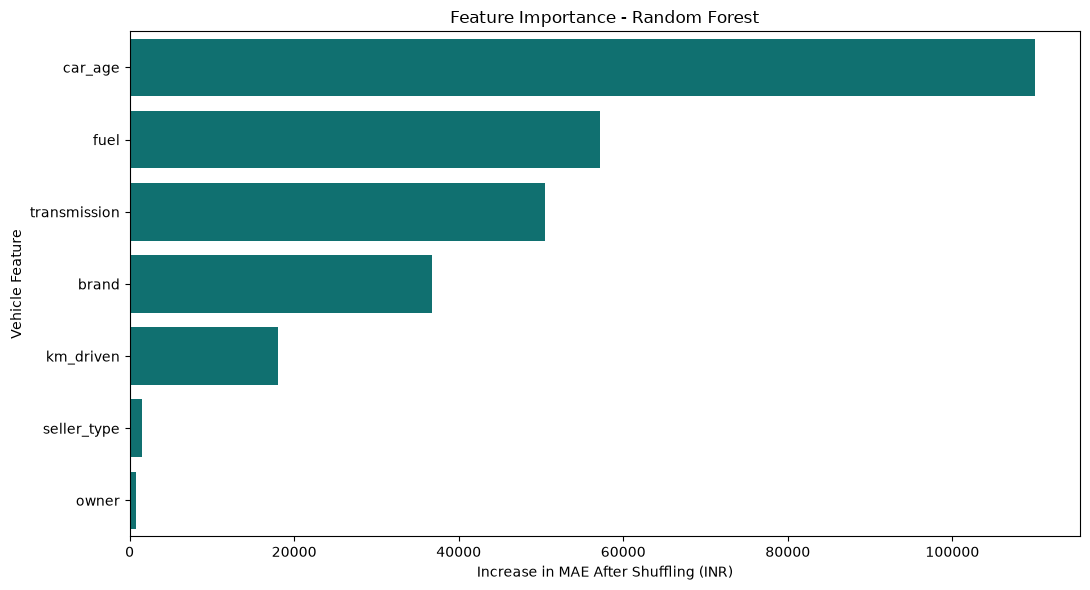

In [81]:
# Visualize feature importance
plt.figure(figsize=(11, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    color="teal"
)

plt.title(
    f"Feature Importance - {best_model_name}"
)

plt.xlabel("Increase in MAE After Shuffling (INR)")
plt.ylabel("Vehicle Feature")

plt.tight_layout()
plt.show()

## 13. Model Evaluation Findings

Two regression algorithms were evaluated using
the same reserved test dataset.

### Linear Regression Results

- MAE: INR 179,642.13
- RMSE: INR 384,722.83
- R² Score: 0.5405

### Random Forest Results

- MAE: INR 156,819.27
- RMSE: INR 359,726.55
- R² Score: 0.5983

### Best-Performing Model

Random Forest Regressor achieved the best predictive
performance across all three evaluation metrics.

Compared with Linear Regression, Random Forest
reduced RMSE by approximately 6.5%.

The Random Forest model also achieved a higher
R² score, explaining approximately 59.83% of the
variation in selling prices within the test dataset.

### Interpretation

The results suggest that Random Forest captures
relationships between vehicle characteristics and
selling prices more effectively than the baseline
Linear Regression model.

However, the model still produces substantial
prediction errors, particularly when considering
the RMSE value.

### Limitations and Future Improvements

1. The dataset contains historical used-car prices.
2. Vehicle condition and service history are not
   represented directly in the selected features.
3. Hyperparameter tuning may improve performance.
4. Cross-validation could provide a more reliable
   estimate of predictive performance.
5. Additional vehicle and market features may
   improve price predictions.

Overall, Random Forest is selected as the
best-performing model for this experiment.

## 14. Final Project Conclusion

### Project Overview

This project developed machine learning regression models
to predict used-car selling prices using the CarDekho dataset.

The project followed a complete machine learning workflow:

1. Data loading and inspection
2. Data cleaning and preprocessing
3. Feature engineering
4. Exploratory Data Analysis
5. Data visualization
6. Categorical feature encoding
7. Model training
8. Model evaluation
9. Feature importance analysis

### Models Developed

Two regression models were trained:

- Linear Regression
- Random Forest Regressor

Both models were evaluated on the same 20% test dataset.

### Model Evaluation Results

**Linear Regression**
- MAE: INR 179,642.13
- RMSE: INR 384,722.83
- R² Score: 0.5405

**Random Forest Regressor**
- MAE: INR 156,819.27
- RMSE: INR 359,726.55
- R² Score: 0.5983

### Best-Performing Model

Random Forest Regressor achieved the best overall
predictive performance.

It produced lower MAE and RMSE values and a higher
R² score compared with Linear Regression.

The Random Forest model explained approximately
59.83% of the variation in the test-set selling prices.

### Feature Importance Findings

Permutation importance analysis showed that
car age was the most influential predictor for
the trained Random Forest model.

Other important features included:

- Fuel type
- Transmission
- Car brand
- Kilometers driven

Seller type and ownership category showed
relatively low permutation importance.

These findings describe model behavior rather
than causal effects on vehicle prices.

### Residual Analysis

Residual analysis showed that prediction errors
were not uniformly distributed.

The model generally performed better for
lower-priced vehicles.

Several expensive vehicles were substantially
underpredicted, indicating difficulty in
estimating higher-value cars.

### Project Limitations

1. The dataset contains historical Indian used-car
   prices rather than current market valuations.

2. Important features such as vehicle condition,
   service history, and accident history are absent.

3. The model was evaluated using a single
   training and testing split.

4. Significant prediction errors remain,
   particularly for expensive vehicles.

### Future Improvements

Future improvements could include:

- Hyperparameter optimization
- Cross-validation
- Additional vehicle characteristics
- Logarithmic transformation of selling prices
- Comparison with gradient boosting models
- Development of an interactive price prediction app

### Final Remarks

This project demonstrated how supervised machine
learning can be applied to used-car price prediction.

It strengthened practical skills in Python,
data preprocessing, feature engineering,
exploratory analysis, regression modeling,
model evaluation, and interpretation.

Random Forest was selected as the best-performing
model for this experiment, while further improvements
are necessary before using it for real-world
vehicle valuation.